In [1]:
import matplotlib;
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import LeaveOneOut
from sklearn.tree import DecisionTreeClassifier

# --- LOOCV One-Shot Revision ---
X, y = make_classification(n_samples=20, n_features=5, n_classes=2, random_state=42)
loo = LeaveOneOut()
clf = DecisionTreeClassifier(random_state=42)
accs = []
for i, (tr, te) in enumerate(loo.split(X)):
    clf.fit(X[tr], y[tr])
    accs.append(int(clf.predict(X[te])[0] == y[te][0]))
print(f'Mean LOOCV Accuracy: {np.mean(accs):.4f}')

# VIVA NOTES:
# 1. LOOCV: n_folds = n_samples - every sample used once as test set
# 2. Most expensive CV - trains n separate models
# 3. Low bias (uses almost all data per fold), but high variance
# 4. Good for small datasets where data is precious
# 5. Mean accuracy = proportion of correct single-sample predictions
# 6. Preferred over k-fold when dataset is very small (n < 50)


Mean LOOCV Accuracy: 0.8500


### Q5
Write a Python code to perform Leave-One-Out Cross-Validation (LOOCV) on a dataset using a Decision Tree Classifier. The dataset consists of features and labels as specified below.

**Dataset Description:**
- The dataset consists of 100 samples with 5 features.
- The target variable is binary (0 or 1).

**Instructions:**
- Import the necessary libraries.
- Load or create a synthetic dataset with the specified characteristics.
- Implement Leave-One-Out Cross-Validation (LOOCV).
- Train a Decision Tree Classifier on each training set and evaluate it on the left-out sample.
- Print the accuracy for each iteration and the average accuracy across all iterations.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import LeaveOneOut
from sklearn.tree import DecisionTreeClassifier


In [ ]:
# Generate synthetic dataset: 100 samples, 5 features, binary target
X, y = make_classification(n_samples=100, n_features=5, n_classes=2, random_state=42)
print(f'Dataset shape: X={X.shape}, y={y.shape}')

Dataset shape: X=(100, 5), y=(100,)
Class distribution: {np.int64(0): np.int64(50), np.int64(1): np.int64(50)}


In [4]:
# LOOCV - each sample left out once as the test set
loo = LeaveOneOut()
clf = DecisionTreeClassifier(random_state=42)
fold_accs = []

for i, (train_idx, test_idx) in enumerate(loo.split(X)):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = int(y_pred[0] == y_test[0])  # 1=correct, 0=wrong
    fold_accs.append(acc)
    print(f'Fold {i+1:3d}: Predicted={y_pred[0]}, Actual={y_test[0]}, Accuracy={acc}')

print(f'\nAverage LOOCV Accuracy: {np.mean(fold_accs):.4f}')


Fold   1: Predicted=0, Actual=0, Accuracy=1
Fold   2: Predicted=1, Actual=1, Accuracy=1
Fold   3: Predicted=0, Actual=0, Accuracy=1
Fold   4: Predicted=0, Actual=0, Accuracy=1
Fold   5: Predicted=1, Actual=1, Accuracy=1
Fold   6: Predicted=1, Actual=1, Accuracy=1
Fold   7: Predicted=0, Actual=0, Accuracy=1
Fold   8: Predicted=0, Actual=0, Accuracy=1
Fold   9: Predicted=1, Actual=1, Accuracy=1
Fold  10: Predicted=1, Actual=1, Accuracy=1
Fold  11: Predicted=1, Actual=1, Accuracy=1
Fold  12: Predicted=1, Actual=1, Accuracy=1
Fold  13: Predicted=1, Actual=1, Accuracy=1
Fold  14: Predicted=0, Actual=1, Accuracy=0
Fold  15: Predicted=0, Actual=0, Accuracy=1
Fold  16: Predicted=1, Actual=1, Accuracy=1
Fold  17: Predicted=0, Actual=0, Accuracy=1
Fold  18: Predicted=1, Actual=1, Accuracy=1
Fold  19: Predicted=0, Actual=0, Accuracy=1
Fold  20: Predicted=0, Actual=0, Accuracy=1
Fold  21: Predicted=1, Actual=0, Accuracy=0
Fold  22: Predicted=1, Actual=1, Accuracy=1
Fold  23: Predicted=1, Actual=1,

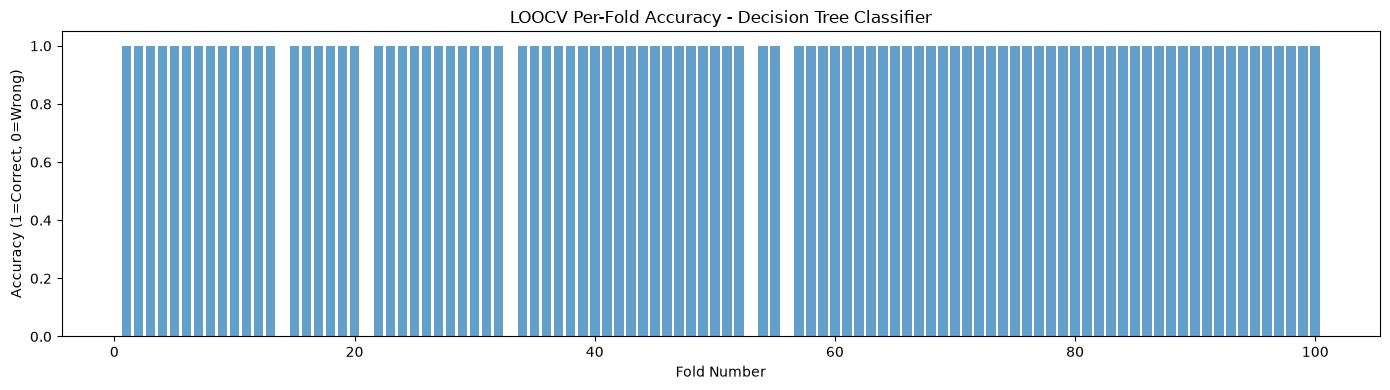

In [8]:
# Bar plot of per-fold accuracy (100 bars)
plt.figure(figsize=(14, 4))
plt.bar(range(1, 101), fold_accs, alpha=0.7)
plt.xlabel('Fold Number')
plt.ylabel('Accuracy (1=Correct, 0=Wrong)')
plt.title('LOOCV Per-Fold Accuracy - Decision Tree Classifier')
plt.tight_layout()
plt.show()
